# Task result loader

This notebook opens an existing policy result store, dispatches to the policy-specific formatter, and inspects the returned `PolicyFormattedResults` payload. Use the dropdown below to select a `.zarr` store under `artifacts/`, ordered by newest first.


In [1]:
import json
import sys
from pathlib import Path

import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from matplotlib.colors import TwoSlopeNorm

project_root = Path.cwd()
if not (project_root / "tasks").exists():
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

try:
    import scienceplots  # noqa: F401
except ModuleNotFoundError:
    scienceplots = None
else:
    plt.style.use("science")
from tasks.policies import load_policy_results
from network_creation.plotting.plot_pair import plot_pair
from network_creation.stats.topology_welfare import normalized_welfare_per_topology

project_root

PosixPath('/home/hdahmou/Network_creation')

In [2]:
def get_welfare_reference(benefit_to_cost_ratio, distance_discount, n):
    reference_welfare_func = lambda topology_class: normalized_welfare_per_topology(
        topology_class=topology_class,
        n=n,
        benefit_to_cost_ratio=benefit_to_cost_ratio,
        distance_discount=distance_discount,
    )
    reference_welfare_max = reference_welfare_func("max")
    reference_welfare = {
        "star": float(reference_welfare_func("star") / reference_welfare_max),
        "empty": float(reference_welfare_func("empty") / reference_welfare_max),
        "random": float(reference_welfare_func("random") / reference_welfare_max),
    }
    return reference_welfare

In [3]:
rng = np.random.default_rng(42)

## Load and transform policy results


In [4]:
result_store_candidates = sorted(
    project_root.glob("artifacts/**/*.zarr"),
    key=lambda path: path.stat().st_mtime,
    reverse=True,
)
if not result_store_candidates:
    raise FileNotFoundError("No .zarr result stores found under artifacts/")

result_store_selector = widgets.Dropdown(
    options=[str(path.relative_to(project_root)) for path in result_store_candidates],
    value=str(result_store_candidates[0].relative_to(project_root)),
    description="Result:",
    layout=widgets.Layout(width="95%"),
)
display(result_store_selector)

Dropdown(description='Result:', layout=Layout(width='95%'), options=('artifacts/best_response_policy/best-resp…

In [5]:
result_store_path = project_root / result_store_selector.value

formatted = load_policy_results(result_store_path)
input_group = formatted.inputs
output_group = formatted.outputs
status_group = formatted.status
metadata = formatted.metadata
config = json.loads(Path(metadata["config_path"]).read_text(encoding="utf-8"))

{
    "result_store_path": str(metadata["result_store_path"]),
    "config_path": str(metadata["config_path"]),
    "task_name": metadata["task_name"],
    "task_class": metadata["task_class"],
    "output_schema": metadata["output_schema"],
    "input_tensors": {
        name: tensor.shape for name, tensor in input_group["tensors"].items()
    },
    "output_tensors": {
        name: tensor.shape for name, tensor in output_group["tensors"].items()
    },
    "status_tensors": {
        name: tensor.shape for name, tensor in status_group["tensors"].items()
    },
}

{'result_store_path': '/home/hdahmou/Network_creation/artifacts/best_response_policy/best-response-policy-20260422T185947.zarr',
 'config_path': '/home/hdahmou/Network_creation/artifacts/best_response_policy/best-response-policy-20260422T185947.dispatch_config.json',
 'task_name': 'best-response-policy',
 'task_class': 'tasks.policies.best_response:BestResponsePolicyRun',
 'output_schema': [{'name': 'central_point_of_dominance.mean',
   'shape': [73],
   'dtype': 'float32'},
  {'name': 'indegree.mean', 'shape': [73], 'dtype': 'float32'},
  {'name': 'distance.mean', 'shape': [73], 'dtype': 'float32'},
  {'name': 'centered_mean_welfare.mean', 'shape': [73], 'dtype': 'float32'}],
 'input_tensors': {'parameters': (1, 32768, 5)},
 'output_tensors': {'timeseries': (1, 32768, 4, 73), 'final': (1, 32768, 4)},
 'status_tensors': {'success': (1, 32768),
  'error': (1, 32768),
  'duration_ms': (1, 32768)}}

In [6]:
{
    "input_dims": input_group["dims"],
    "output_dims": output_group["dims"],
    "input_label_sizes": {
        name: len(values) for name, values in input_group["labels"].items()
    },
    "output_label_sizes": {
        name: len(values) for name, values in output_group["labels"].items()
    },
}

{'input_dims': {'parameters': ('n_agents', 'parameter_row', 'parameter')},
 'output_dims': {'timeseries': ('n_agents',
   'parameter_row',
   'observable',
   'step'),
  'final': ('n_agents', 'parameter_row', 'observable')},
 'input_label_sizes': {'n_agents': 1, 'parameter_row': 32768, 'parameter': 5},
 'output_label_sizes': {'n_agents': 1,
  'parameter_row': 32768,
  'observable': 4,
  'step': 73}}

In [7]:
success = status_group["tensors"]["success"]
error = status_group["tensors"]["error"]
duration_ms = status_group["tensors"]["duration_ms"]
failed_coords = np.argwhere(~success)

{
    "success_shape": tuple(success.shape),
    "failure_count": int((~success).sum()),
    "failed_cells": [
        {
            "n_agents": int(input_group["labels"]["n_agents"][n_agents_index]),
            "parameter_row": int(
                output_group["labels"]["parameter_row"][parameter_row_index]
            ),
            "error": str(error[n_agents_index, parameter_row_index]),
            "duration_ms": float(duration_ms[n_agents_index, parameter_row_index]),
        }
        for n_agents_index, parameter_row_index in failed_coords
    ],
}

{'success_shape': (1, 32768), 'failure_count': 0, 'failed_cells': []}

## Plot per-step outputs


In [8]:
timeseries = output_group["tensors"]["timeseries"]
success = status_group["tensors"]["success"]
observables = tuple(output_group["labels"]["observable"])
steps = np.asarray(output_group["labels"]["step"])
n_agents_values = np.asarray(output_group["labels"]["n_agents"])
parameter_rows = np.asarray(output_group["labels"]["parameter_row"])

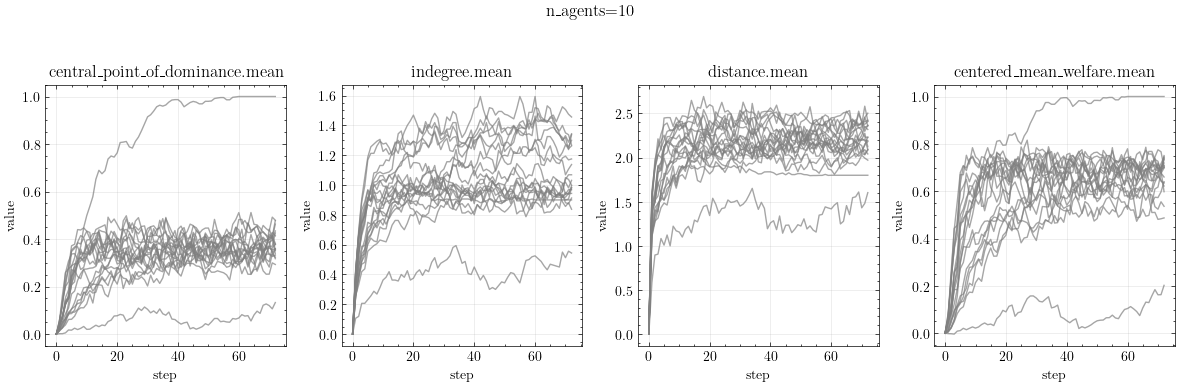

In [9]:
for n_agents_index, n_agents in enumerate(n_agents_values):
    fig, axes = plt.subplots(1, len(observables), figsize=(12, 4), sharex=True)
    axes = np.atleast_1d(axes)

    valid_indices = np.flatnonzero(success[n_agents_index])

    n_subset = min(20, len(valid_indices))
    chosen_indices = rng.choice(valid_indices, size=n_subset, replace=False)

    for observable_index, observable_name in enumerate(observables):
        for parameter_row_index in chosen_indices:
            parameter_row = parameter_rows[parameter_row_index]
            axes[observable_index].plot(
                steps,
                timeseries[n_agents_index, parameter_row_index, observable_index],
                alpha=0.7,
                label=f"row={int(parameter_row)}",
                c="gray",
            )

        axes[observable_index].set_title(str(observable_name))
        axes[observable_index].set_xlabel("step")
        axes[observable_index].set_ylabel("value")
        axes[observable_index].grid(alpha=0.3)

    fig.suptitle(f"n_agents={int(n_agents)}")
    handles, labels = axes[0].get_legend_handles_labels()
    plt.tight_layout(rect=(0, 0, 1, 0.94))
    plt.show()

## Pair plots


In [10]:
parameters_grid = input_group["tensors"]["parameters"]
final_grid = output_group["tensors"]["final"]
parameter_labels = tuple(input_group["labels"].get("parameter", ()))
observable_labels = tuple(output_group["labels"]["observable"])
n_agents_values = np.asarray(input_group["labels"]["n_agents"])

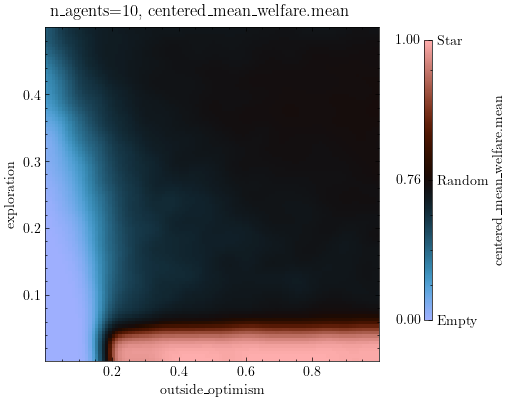

In [11]:
target_idx = -1

for target_n_agents_index, selected_n_agents in enumerate(n_agents_values):
    success = status_group["tensors"]["success"][target_n_agents_index]
    parameters = parameters_grid[target_n_agents_index][success]
    final = final_grid[target_n_agents_index][success]

    benefit_to_cost_ratio = np.unique(
        parameters[:, parameter_labels.index("benefit_to_cost_ratio")]
    ).item()
    distance_discount = np.unique(
        parameters[:, parameter_labels.index("distance_discount")]
    ).item()

    reference_welfare = get_welfare_reference(
        benefit_to_cost_ratio=benefit_to_cost_ratio,
        distance_discount=distance_discount,
        n=selected_n_agents,
    )

    target_values = final[:, target_idx]
    target_norm = TwoSlopeNorm(
        vmin=reference_welfare["empty"],
        vcenter=reference_welfare["random"],
        vmax=reference_welfare["star"],
    )
    fig, axes = plot_pair(
        X=parameters,
        y=target_values,
        labels=parameter_labels,
        label_y=observable_labels[target_idx],
        atol=1e-5,
        base_fig_size=4.0,
        cmap="berlin",
        method="gaussian",
        resolution=100,
        sigma=2.5,
        norm=target_norm,
        point_size=3,
    )

    cbar_ax = fig.axes[-1]
    vals = [
        reference_welfare["empty"],
        reference_welfare["random"],
        reference_welfare["star"],
    ]
    cbar_ax.set_yticks(vals, labels=["Empty", "Random", "Star"])
    cbar_ax.tick_params(labelright=True, labelleft=False)
    pos = cbar_ax.get_position()
    cbar_ax.set_position([pos.x0 + 0.04, pos.y0, pos.width, pos.height])
    # cbar_ax.yaxis.tick_right()
    for v in vals:
        cbar_ax.text(
            -0.35,
            v,
            f"{v:.2f}",
            transform=cbar_ax.get_yaxis_transform(),
            ha="right",
            va="center",
        )

    fig.suptitle(f"n_agents={selected_n_agents}, {observable_labels[target_idx]}")

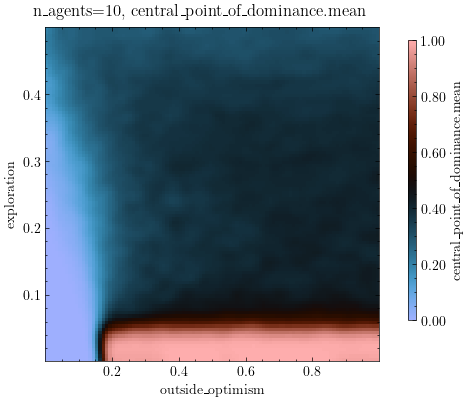

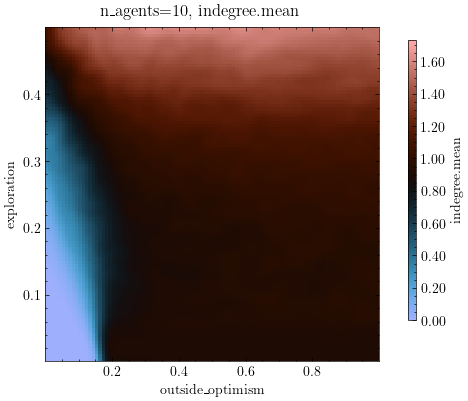

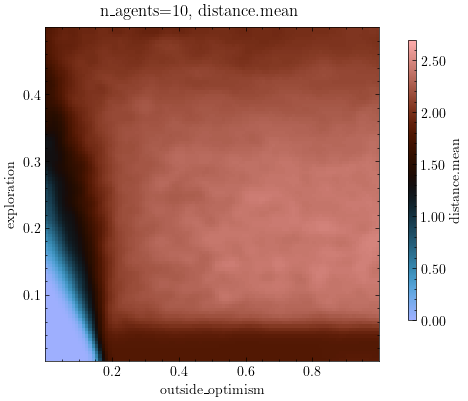

In [12]:
for target_idx in range(len(observable_labels) - 1):
    for target_n_agents_index, selected_n_agents in enumerate(n_agents_values):
        success = status_group["tensors"]["success"][target_n_agents_index]
        parameters = parameters_grid[target_n_agents_index][success]
        final = final_grid[target_n_agents_index][success]
        target_values = final[:, target_idx]
        fig, axes = plot_pair(
            X=parameters,
            y=target_values,
            labels=parameter_labels,
            label_y=observable_labels[target_idx],
            atol=1e-5,
            base_fig_size=4.0,
            cmap="berlin",
            method="gaussian",
            resolution=100,
            # sigma=0.1,
            point_size=1,
        )
        fig.suptitle(f"n_agents={selected_n_agents}, {observable_labels[target_idx]}")